# Data and chronological split

This notebook examines the dataset used by Shiki RecSys and validates the chronological train/validation/test split.

Goals:

- summarize the interaction and catalog data;
- inspect the evaluation cohort;
- verify the temporal split;
- inspect positive validation and test targets.

All data loading and preprocessing reuse the production project code.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from shiki_recsys.config.settings import get_settings
from shiki_recsys.config.training import load_training_config
from shiki_recsys.database.session import (
    create_database_engine,
    create_session_factory,
)
from shiki_recsys.evaluation.ground_truth import build_positive_items_by_user
from shiki_recsys.preprocessing.splitting import chronological_split
from shiki_recsys.training.data import load_training_data

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
    os.chdir(PROJECT_ROOT)

PROJECT_ROOT

PosixPath('/home/nika/shiki_recsys')

## Data loading

Training data is loaded from PostgreSQL through the same repository and preprocessing pipeline used by production model training.

In [2]:
config = load_training_config(PROJECT_ROOT / "configs" / "training.yaml")
settings = get_settings()

engine = create_database_engine(settings)
session_factory = create_session_factory(engine)

try:
    with session_factory() as session:
        data = load_training_data(session)
finally:
    engine.dispose()

interactions = data.interactions
catalog = data.catalog

## Dataset overview

The dataset contains user-anime interactions together with the anime catalog used by the recommendation models.

In [3]:
data_summary = pd.Series(
    {
        "interactions": len(interactions),
        "users": interactions["user_id"].nunique(),
        "catalog_items": len(catalog),
        "interacted_items": interactions["anime_id"].nunique(),
        "first_interaction": interactions["updated_at"].min(),
        "last_interaction": interactions["updated_at"].max(),
    },
    name="value",
)

data_summary

interactions                           1093527
users                                     1001
catalog_items                            23802
interacted_items                         23715
first_interaction    2012-06-24 16:58:36+00:00
last_interaction     2026-08-17 14:05:00+00:00
Name: value, dtype: object

## Chronological split

Interactions are split independently for each user in chronological order. The same splitting implementation and configuration are used by the training pipeline.

In [4]:
split_config = config.dataset.split

split = chronological_split(
    interactions,
    validation_fraction=split_config.validation_fraction,
    test_fraction=split_config.test_fraction,
    min_interactions_per_user=split_config.min_interactions_per_user,
)

In [5]:
split_summary = pd.DataFrame(
    {
        "interactions": [
            len(split.train),
            len(split.validation),
            len(split.test),
        ],
        "users": [
            split.train["user_id"].nunique(),
            split.validation["user_id"].nunique(),
            split.test["user_id"].nunique(),
        ],
    },
    index=[
        "train",
        "validation",
        "test",
    ],
)

split_summary["fraction"] = split_summary["interactions"] / len(interactions)

split_summary

,interactions,users,fraction
train,875697,1001,0.800801
validation,108915,1001,0.099600
test,108915,1001,0.099600


In [6]:
pd.Series(
    {
        "evaluation_users": len(split.evaluation_user_ids),
        "train_only_users": len(split.train_only_user_ids),
        "evaluation_user_fraction": (
            len(split.evaluation_user_ids) / interactions["user_id"].nunique()
        ),
    },
    name="value",
)

evaluation_users            1001.0
train_only_users               0.0
evaluation_user_fraction       1.0
Name: value, dtype: float64

## Positive future targets

An interaction is considered a positive target when its rating meets the configured positive-rating threshold. Users without positive future targets are excluded from preference-ranking metrics such as Recall@K and NDCG@K.

In [7]:
positive_rating_threshold = config.target.positive_rating_threshold

validation_positive_items = build_positive_items_by_user(
    split.validation,
    positive_rating_threshold=positive_rating_threshold,
)
test_positive_items = build_positive_items_by_user(
    split.test,
    positive_rating_threshold=positive_rating_threshold,
)

pd.DataFrame(
    {
        "users_with_positive_targets": [
            len(validation_positive_items),
            len(test_positive_items),
        ],
        "positive_targets": [
            sum(map(len, validation_positive_items.values())),
            sum(map(len, test_positive_items.values())),
        ],
    },
    index=[
        "validation",
        "test",
    ],
)

,users_with_positive_targets,positive_targets
validation,952,21850
test,942,20977


## Temporal split validation

The split is performed independently for each user. Training interactions must not occur after validation interactions, and validation interactions must not occur after test interactions.

In [8]:
split_boundaries = pd.concat(
    [
        split.train.groupby("user_id")["updated_at"].max().rename("train_end"),
        split.validation.groupby("user_id")["updated_at"]
        .min()
        .rename("validation_start"),
        split.validation.groupby("user_id")["updated_at"]
        .max()
        .rename("validation_end"),
        split.test.groupby("user_id")["updated_at"].min().rename("test_start"),
    ],
    axis=1,
)

temporal_violations = split_boundaries[
    (split_boundaries["train_end"] > split_boundaries["validation_start"])
    | (split_boundaries["validation_end"] > split_boundaries["test_start"])
]

pd.Series(
    {
        "checked_users": len(split_boundaries),
        "temporal_violations": len(temporal_violations),
    },
    name="value",
)

checked_users          1001
temporal_violations       0
Name: value, dtype: int64

No temporal-order violations were found across the 1,001 evaluation users. This confirms that later validation and test interactions do not precede the history available to the models.

## User history and target distributions

User history length determines how much preference information is available to personalized retrievers. The number of positive future items also affects the interpretation of ranking metrics such as Recall@K.

The following distributions characterize the evaluation population before model experiments.

In [9]:
history_sizes = split.train.groupby("user_id").size().rename("train_interactions")

validation_positive_counts = pd.Series(
    {user_id: len(items) for user_id, items in validation_positive_items.items()},
    name="validation_positive_targets",
)

test_positive_counts = pd.Series(
    {user_id: len(items) for user_id, items in test_positive_items.items()},
    name="test_positive_targets",
)

user_statistics = pd.concat(
    [
        history_sizes,
        validation_positive_counts,
        test_positive_counts,
    ],
    axis=1,
).fillna(0)

user_statistics[
    [
        "train_interactions",
        "validation_positive_targets",
        "test_positive_targets",
    ]
].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])

,train_interactions,validation_positive_targets,test_positive_targets
count,1001.000000,1001.000000,1001.000000
mean,874.822178,21.828172,20.956044
std,1415.364386,25.871537,27.618184
min,8.000000,0.000000,0.000000
10%,141.000000,2.000000,1.000000
25%,282.000000,6.000000,6.000000
50%,574.000000,15.000000,13.000000
75%,976.000000,29.000000,28.000000
90%,1658.000000,49.000000,47.000000
max,18446.000000,340.000000,368.000000


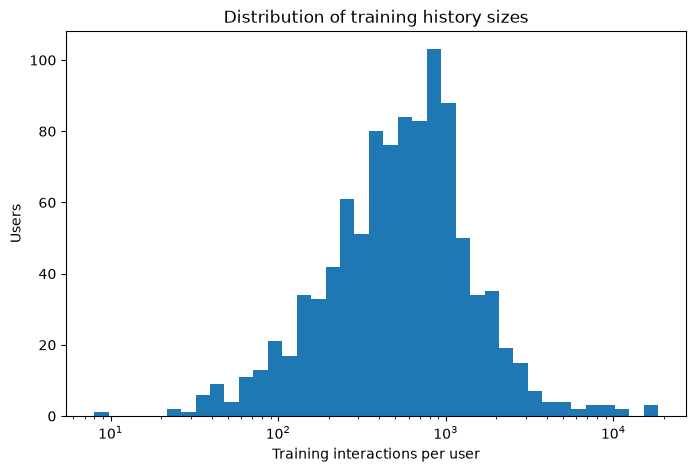

In [10]:
train_history = user_statistics["train_interactions"]

plt.figure(figsize=(8, 5))
plt.hist(
    train_history,
    bins=np.logspace(
        np.log10(train_history.min()),
        np.log10(train_history.max()),
        40,
    ),
)
plt.xscale("log")
plt.xlabel("Training interactions per user")
plt.ylabel("Users")
plt.title("Distribution of training history sizes")
plt.show()

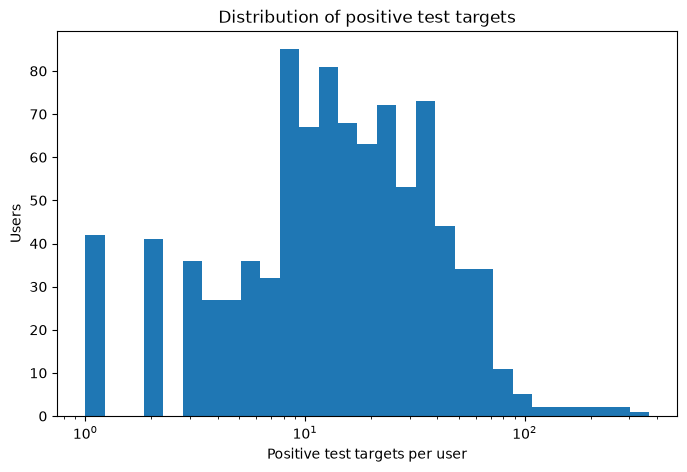

In [11]:
positive_test_targets = user_statistics.loc[
    user_statistics["test_positive_targets"] > 0,
    "test_positive_targets",
]

plt.figure(figsize=(8, 5))
plt.hist(
    positive_test_targets,
    bins=np.logspace(
        np.log10(positive_test_targets.min()),
        np.log10(positive_test_targets.max()),
        30,
    ),
)
plt.xscale("log")
plt.xlabel("Positive test targets per user")
plt.ylabel("Users")
plt.title("Distribution of positive test targets")
plt.show()

The evaluation population is strongly right-skewed. The median training history contains 574 interactions, while a small number of highly active users have several thousand interactions, with a maximum of 18,446.

Positive future targets follow a similar pattern. The median user has 13 positive test targets, while the largest test target set contains 368 items.

This imbalance motivates user-level macro averaging for ranking metrics: each user contributes equally regardless of history or target-set size.

All 1,001 users satisfy the minimum-history requirement and can be chronologically split. However, only 952 validation users and 942 test users have at least one positive future target. Users without positive targets are excluded from preference-ranking metrics.

## Conclusions

- The dataset contains 1,093,527 interactions from 1,001 users and 23,802 catalog items.
- All 1,001 users satisfy the minimum-history requirement and are included in the chronological evaluation split.
- No temporal-order violations were found between train, validation, and test interactions.
- Positive future targets are available for 952 validation users and 942 test users; users without positive targets are excluded from preference-ranking metrics.
- User histories and positive target-set sizes are strongly right-skewed, with a small number of substantially more active users.
- Ranking metrics are therefore macro-averaged at the user level so that highly active users do not dominate the evaluation.
- The current chronological cohort contains no train-only users, so sparse and cold-start behavior must be evaluated separately by constructing reduced-history scenarios.